# Лабораторная работа №6: Построение и оценка VLM-пайплайна

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


In [1]:
# Ячейка 1: установка библиотек (выполняется один раз)
!pip install -q transformers accelerate bitsandbytes qwen-vl-utils datasets pillow

## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


### Математическая постановка

Для открытых ответов одной exact match недостаточно. Используют нормализованный EM/F1, judge rubric и ручную разметку ошибок. Hallucination rate: $H=N_{unsupported}/N_{claims}$.


### Материалы

- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal)
- [VLMEvalKit](https://github.com/open-compass/VLMEvalKit)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [2]:
# Ячейка 2: базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time, re
import numpy as np
from PIL import Image
from datasets import load_dataset

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

import torch
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def check(condition, message):
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "artifacts": str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts'}


In [3]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# Ячейка 3: надёжная загрузка PixMo (captioning, VQA, OCR, counting) + fallback
from pathlib import Path
import os, json, random, re, time
import numpy as np
from PIL import Image
from collections import Counter

# --- базовые константы (переинициализуем на случай, если ячейка 2 не запускалась) ---
SEED = 42
FAST_DEV_RUN = False                       # True — только smoke-тест
ARTIFACTS = Path.cwd() / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

N_PER_TASK = 5 if not FAST_DEV_RUN else 1
FETCH_N    = 80 if not FAST_DEV_RUN else 8

# ---------------------------------------------------------------- fallback
def build_fallback():
    """Заглушки, если датасеты недоступны. НЕ отчётные данные."""
    fb = {
        "captioning": [("Describe this image in detail.", "A gray placeholder.")],
        "vqa":        [("What is the main color?", "Gray.")],
        "ocr":        [("What text is visible?", "None.")],
        "counting":   [("How many objects are visible?", "1")],
    }
    out = []
    for t, pairs in fb.items():
        for j in range(N_PER_TASK):
            q, a = pairs[j % len(pairs)]
            out.append({
                "id": f"{t}_{j}", "task_type": t,
                "image": Image.new("RGB", (224, 224), color=(128, 128, 128)),
                "question": q, "reference": a,
                "provenance": {"dataset": "fallback", "split": "local",
                               "index": j, "license": "n/a"},
            })
    return out

# ---------------------------------------------------------------- утилиты
try:
    from datasets import load_dataset
    import requests
    from io import BytesIO
    _HF_OK = True
except Exception as _e:
    print(f"⚠ Импорт datasets/requests не удался: {_e}")
    _HF_OK = False

if _HF_OK:
    def _download(url):
        if not url: return None
        try:
            r = requests.get(url, timeout=15); r.raise_for_status()
            return Image.open(BytesIO(r.content)).convert("RGB")
        except Exception:
            return None

    def _extract_image(ex):
        """PIL Image из image/images/img, иначе скачать по image_url/url."""
        for k in ("image", "images", "img"):
            if k in ex and ex[k] is not None:
                v = ex[k]
                if isinstance(v, Image.Image): return v
                if isinstance(v, list) and v and isinstance(v[0], Image.Image): return v[0]
        for k in ("image_url", "url"):
            if k in ex and ex[k]:
                u = ex[k]
                if isinstance(u, list): u = u[0] if u else None
                if u: return _download(u)
        return None

    def _first(x): return x[0] if isinstance(x, list) and x else x

    def _try_load(name, fetch_n=80, config_name=None):
        try:
            kwargs = dict(split=f"train[:{fetch_n}]")
            if config_name is not None:
                kwargs["name"] = config_name
            ds = load_dataset(name, **kwargs)
            print(f"  ✔ {name} (config={config_name}): {ds.column_names}")
            return ds
        except Exception as e:
            print(f"  ✘ {name} (config={config_name}): {e}")
            return None

# ---------------------------------------------------------------- загрузка
eval_examples = []

# --- 1. Captioning: PixMo-Cap ---------------------------------------------
if _HF_OK:
    try:
        ds = _try_load("allenai/pixmo-cap", FETCH_N)
        if ds:
            got = 0
            for i, ex in enumerate(ds):
                if got >= N_PER_TASK: break
                img = _extract_image(ex)
                ref = ex.get("caption") or ex.get("dense_caption") or ""
                if img is None or not ref: continue
                eval_examples.append({
                    "id": f"cap_{got}", "task_type": "captioning", "image": img,
                    "question": "Describe this image in detail.", "reference": ref,
                    "provenance": {"dataset": "allenai/pixmo-cap", "split": "train",
                                   "index": i, "license": "odc-by"},
                })
                got += 1
            print(f"  cap: {got}/{N_PER_TASK}")
    except Exception as e:
        print(f"  ✘ блок captioning упал: {e}")

# --- 2. VQA: PixMo-AskModelAnything ---------------------------------------
if _HF_OK:
    try:
        ds = _try_load("allenai/pixmo-ask-model-anything", FETCH_N)
        if ds:
            got = 0
            for i, ex in enumerate(ds):
                if got >= N_PER_TASK: break
                img = _extract_image(ex)
                if img is None: continue
                q = _first(ex.get("question") or ex.get("questions"))
                a = _first(ex.get("answer")   or ex.get("answers"))
                if not q or not a: continue
                eval_examples.append({
                    "id": f"vqa_{got}", "task_type": "vqa", "image": img,
                    "question": q, "reference": a,
                    "provenance": {"dataset": "allenai/pixmo-ask-model-anything",
                                   "split": "train", "index": i, "license": "odc-by"},
                })
                got += 1
            print(f"  vqa: {got}/{N_PER_TASK}")
    except Exception as e:
        print(f"  ✘ блок VQA упал: {e}")

# --- 3. OCR: PixMo-Docs ----------------------------------------------------
#     ВАЖНО: у датасета НЕТ дефолтного конфига (charts/diagrams/tables/other).
#     Поле "questions" — СЛОВАРЬ {"question": [...], "answer": [...]}.
if _HF_OK:
    ocr_target = N_PER_TASK
    for config_name in ("charts", "diagrams", "tables", "other"):
        try:
            already = sum(1 for e in eval_examples if e["task_type"] == "ocr")
            if already >= ocr_target:
                break

            ds = _try_load("allenai/pixmo-docs", FETCH_N, config_name=config_name)
            if not ds:
                continue

            got = 0
            for i, ex in enumerate(ds):
                already = sum(1 for e in eval_examples if e["task_type"] == "ocr")
                if already >= ocr_target or got >= ocr_target:
                    break

                img = _extract_image(ex)
                qa_dict = ex.get("questions") or {}

                # Правильная структура: два параллельных списка
                questions_list = qa_dict.get("question") or []
                answers_list   = qa_dict.get("answer")   or []
                if img is None or not questions_list or not answers_list:
                    continue

                q = questions_list[0]
                a = answers_list[0]
                if not q or not a:
                    continue

                idx_ocr = sum(1 for e in eval_examples if e["task_type"] == "ocr")
                eval_examples.append({
                    "id": f"ocr_{config_name}_{idx_ocr}",
                    "task_type": "ocr",
                    "image": img,
                    "question": q,
                    "reference": a,
                    "provenance": {"dataset": "allenai/pixmo-docs",
                                   "config": config_name, "split": "train",
                                   "index": i, "license": "odc-by"},
                })
                got += 1
            print(f"  ocr/{config_name}: {got}")
        except Exception as e:
            print(f"  ✘ блок OCR/{config_name} упал: {e}")

# --- 4. Counting: PixMo-Count ---------------------------------------------
#     Поля: image_url, count, label
if _HF_OK:
    try:
        ds = _try_load("allenai/pixmo-count", FETCH_N)
        if ds:
            got = 0
            for i, ex in enumerate(ds):
                if got >= N_PER_TASK: break
                img = _extract_image(ex)
                if img is None: continue
                label = ex.get("label") or ex.get("object") or "objects"
                cnt = ex.get("count")
                if cnt is None: continue
                eval_examples.append({
                    "id": f"count_{got}", "task_type": "counting", "image": img,
                    "question": f"How many {label} are in the image?",
                    "reference": str(cnt),
                    "provenance": {"dataset": "allenai/pixmo-count",
                                   "split": "train", "index": i, "license": "odc-by"},
                })
                got += 1
            print(f"  count: {got}/{N_PER_TASK}")
    except Exception as e:
        print(f"  ✘ блок counting упал: {e}")

# ---------------------------------------------------------------- fallback
if not eval_examples:
    print("⚠ PixMo недоступен — использую fallback (заглушки). "
          "Для отчётного прогона нужны реальные данные.")
    eval_examples = build_fallback()

# ---------------------------------------------------------------- проверки
assert isinstance(eval_examples, list) and len(eval_examples) > 0, \
    "eval_examples пуста после всех попыток!"

cnt = Counter(e["task_type"] for e in eval_examples)
print(f"\n✔ eval_examples: {len(eval_examples)} шт | {dict(cnt)}")

missing = [t for t in ("captioning", "vqa", "ocr", "counting") if cnt[t] == 0]
if missing:
    raise AssertionError(
        f"Не все типы задач представлены: {dict(cnt)}; отсутствуют: {missing}. "
        "Проверьте вывод выше — какой датасет вернул ошибку."
    )

# ---------------------------------------------------------------- eval.jsonl
with open(ARTIFACTS / "eval.jsonl", "w", encoding="utf-8") as f:
    for ex in eval_examples:
        f.write(json.dumps({k: v for k, v in ex.items() if k != "image"},
                           ensure_ascii=False) + "\n")
print(f"✔ eval.jsonl → {ARTIFACTS.resolve() / 'eval.jsonl'}")

README.md:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

data/train-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  275MB            

data/train-00000-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  276MB            

data/train-00001-of-00004.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  275MB            

... (125 outputs left out)

Generating validation split:   0%|          | 0/540 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36916 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/540 [00:00<?, ? examples/s]

  ✔ allenai/pixmo-count (config=None): ['image_url', 'image_sha256', 'count', 'points', 'label']
  count: 5/5

✔ eval_examples: 20 шт | {'captioning': 5, 'vqa': 5, 'ocr': 5, 'counting': 5}
✔ eval.jsonl → /content/artifacts/eval.jsonl


### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# Ячейка 4: загрузка Qwen2-VL-2B-Instruct с NF4
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from qwen_vl_utils import process_vision_info

model_id = "Qwen/Qwen2-VL-2B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True
)
processor = AutoProcessor.from_pretrained(
    model_id,
    trust_remote_code=True,
    min_pixels=28*28,
    max_pixels=280*280
)

check(model is not None and processor is not None, "Модель и процессор загружены")
check(torch.cuda.is_available(), "GPU доступен, квантизация NF4 активна")

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

✔ Модель и процессор загружены
✔ GPU доступен, квантизация NF4 активна


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# Ячейка 5: build_prompt и run_vlm
def build_prompt(image, question, system_prompt=None):
    """Собирает сообщение с изображением и вопросом."""
    messages = []
    if system_prompt:
        messages.append({"role": "system", "content": system_prompt})
    messages.append({
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": question}
        ]
    })
    return messages

def run_vlm(image, question, system_prompt=None, max_new_tokens=64, do_sample=False, temperature=1.0):
    """Выполняет инференс и возвращает сырой ответ + время."""
    messages = build_prompt(image, question, system_prompt)
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(text=[text], images=image_inputs, videos=video_inputs,
                       padding=True, return_tensors="pt").to(DEVICE)

    start = time.time()
    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature if do_sample else None
        )
    latency = time.time() - start

    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    return {
        "raw_response": output_text,
        "latency_sec": round(latency, 3),
        "decoding": {"do_sample": do_sample, "temperature": temperature if do_sample else None,
                     "max_new_tokens": max_new_tokens}
    }

# Проверка на одном примере
test_out = run_vlm(eval_examples[0]["image"], eval_examples[0]["question"])
print(test_out)
check("raw_response" in test_out and "latency_sec" in test_out, "run_vlm возвращает сырой ответ и время")

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


{'raw_response': 'The image depicts a bird perched on a blue and white painted wall. The bird has a striking appearance, with a predominantly black plumage that transitions to a blueish-gray on its wings and tail. Its beak is elongated and pointed, with a slight curve at the end, and it has a yellowish', 'latency_sec': 6.487, 'decoding': {'do_sample': False, 'temperature': None, 'max_new_tokens': 64}}
✔ run_vlm возвращает сырой ответ и время


### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
# Ячейка 6: генерация предсказаний с возможностью продолжения
PRED_PATH = ARTIFACTS / "predictions.jsonl"
DONE_IDS = set()
if PRED_PATH.exists():
    with open(PRED_PATH, "r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            DONE_IDS.add(rec["id"])
    print(f"Найдено已完成 предсказаний: {len(DONE_IDS)}")

with open(PRED_PATH, "a", encoding="utf-8") as f:
    for ex in eval_examples:
        if ex["id"] in DONE_IDS:
            continue
        out = run_vlm(ex["image"], ex["question"])
        record = {
            "id": ex["id"],
            "task_type": ex["task_type"],
            "question": ex["question"],
            "reference": ex["reference"],
            "raw_response": out["raw_response"],
            "latency_sec": out["latency_sec"],
            "decoding": out["decoding"]
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")
        f.flush()
        print(f"✔ {ex['id']} обработан")

# Сохраняем также predictions.json
predictions = []
with open(PRED_PATH, "r", encoding="utf-8") as f:
    predictions = [json.loads(line) for line in f]
with open(ARTIFACTS / "predictions.json", "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

check(len(predictions) == len(eval_examples), f"Все {len(eval_examples)} примеров имеют предсказания")

✔ cap_0 обработан
✔ cap_1 обработан
✔ cap_2 обработан
✔ cap_3 обработан
✔ cap_4 обработан
✔ vqa_0 обработан
✔ vqa_1 обработан
✔ vqa_2 обработан
✔ vqa_3 обработан
✔ vqa_4 обработан
✔ ocr_charts_0 обработан
✔ ocr_charts_1 обработан
✔ ocr_charts_2 обработан
✔ ocr_charts_3 обработан
✔ ocr_charts_4 обработан
✔ count_0 обработан
✔ count_1 обработан
✔ count_2 обработан
✔ count_3 обработан
✔ count_4 обработан
✔ Все 20 примеров имеют предсказания


### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Ячейка 7: нормализация и метрики EM/F1
def normalize_answer(s):
    s = s.lower().strip()
    s = re.sub(r"[^\w\s]", "", s)
    s = re.sub(r"\s+", " ", s)
    return s

def exact_match(pred, ref):
    return float(normalize_answer(pred) == normalize_answer(ref))

def f1_score(pred, ref):
    pred_tokens = normalize_answer(pred).split()
    ref_tokens = normalize_answer(ref).split()
    common = set(pred_tokens) & set(ref_tokens)
    if not common:
        return 0.0
    precision = len(common) / len(pred_tokens) if pred_tokens else 0
    recall = len(common) / len(ref_tokens) if ref_tokens else 0
    return 2 * precision * recall / (precision + recall)

metrics = {}
for task in ["vqa", "ocr", "counting"]:
    subset = [p for p in predictions if p["task_type"] == task]
    if not subset:
        continue
    ems = [exact_match(p["raw_response"], p["reference"]) for p in subset]
    f1s = [f1_score(p["raw_response"], p["reference"]) for p in subset]
    metrics[task] = {
        "n": len(subset),
        "exact_match": round(np.mean(ems), 4),
        "f1": round(np.mean(f1s), 4)
    }

with open(ARTIFACTS / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print(json.dumps(metrics, indent=2))
check(len(metrics) >= 3, "metrics.json содержит EM/F1 для VQA, OCR и counting")

{
  "vqa": {
    "n": 5,
    "exact_match": 0.0,
    "f1": 0.2029
  },
  "ocr": {
    "n": 5,
    "exact_match": 0.2,
    "f1": 0.5335
  },
  "counting": {
    "n": 5,
    "exact_match": 0.0,
    "f1": 0.0
  }
}
✔ metrics.json содержит EM/F1 для VQA, OCR и counting


### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Ячейка 8: создание формы ручной разметки (не перезаписывает существующие поля)
REVIEW_PATH = ARTIFACTS / "manual_review.jsonl"
if not REVIEW_PATH.exists():
    with open(REVIEW_PATH, "w", encoding="utf-8") as f:
        for pred in predictions:
            record = {
                "id": pred["id"],
                "task_type": pred["task_type"],
                "question": pred["question"],
                "reference": pred["reference"],
                "raw_response": pred["raw_response"],
                "correctness": None,          # "correct", "partially_correct", "incorrect"
                "error_type": None,           # "hallucination", "counting", "spatial", "ocr", "other"
                "notes": ""
            }
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    print("Создан manual_review.jsonl")
else:
    print("manual_review.jsonl уже существует, поля разметки сохранены")

with open(REVIEW_PATH, "r", encoding="utf-8") as f:
    review_records = [json.loads(line) for line in f]
filled = sum(1 for r in review_records if r["correctness"] is not None)
pending = len(review_records) - filled
print(f"Заполнено: {filled}, ожидает оценки: {pending}")
check(True, "Форма ручной разметки готова (требуется ручное заполнение)")

Создан manual_review.jsonl
Заполнено: 0, ожидает оценки: 20
✔ Форма ручной разметки готова (требуется ручное заполнение)


### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Запись 20 / 20
ID:     count_4
Задача: counting
Вопрос: How many people are in the image?
Эталон: 2
Ответ:  There are two people in the image.


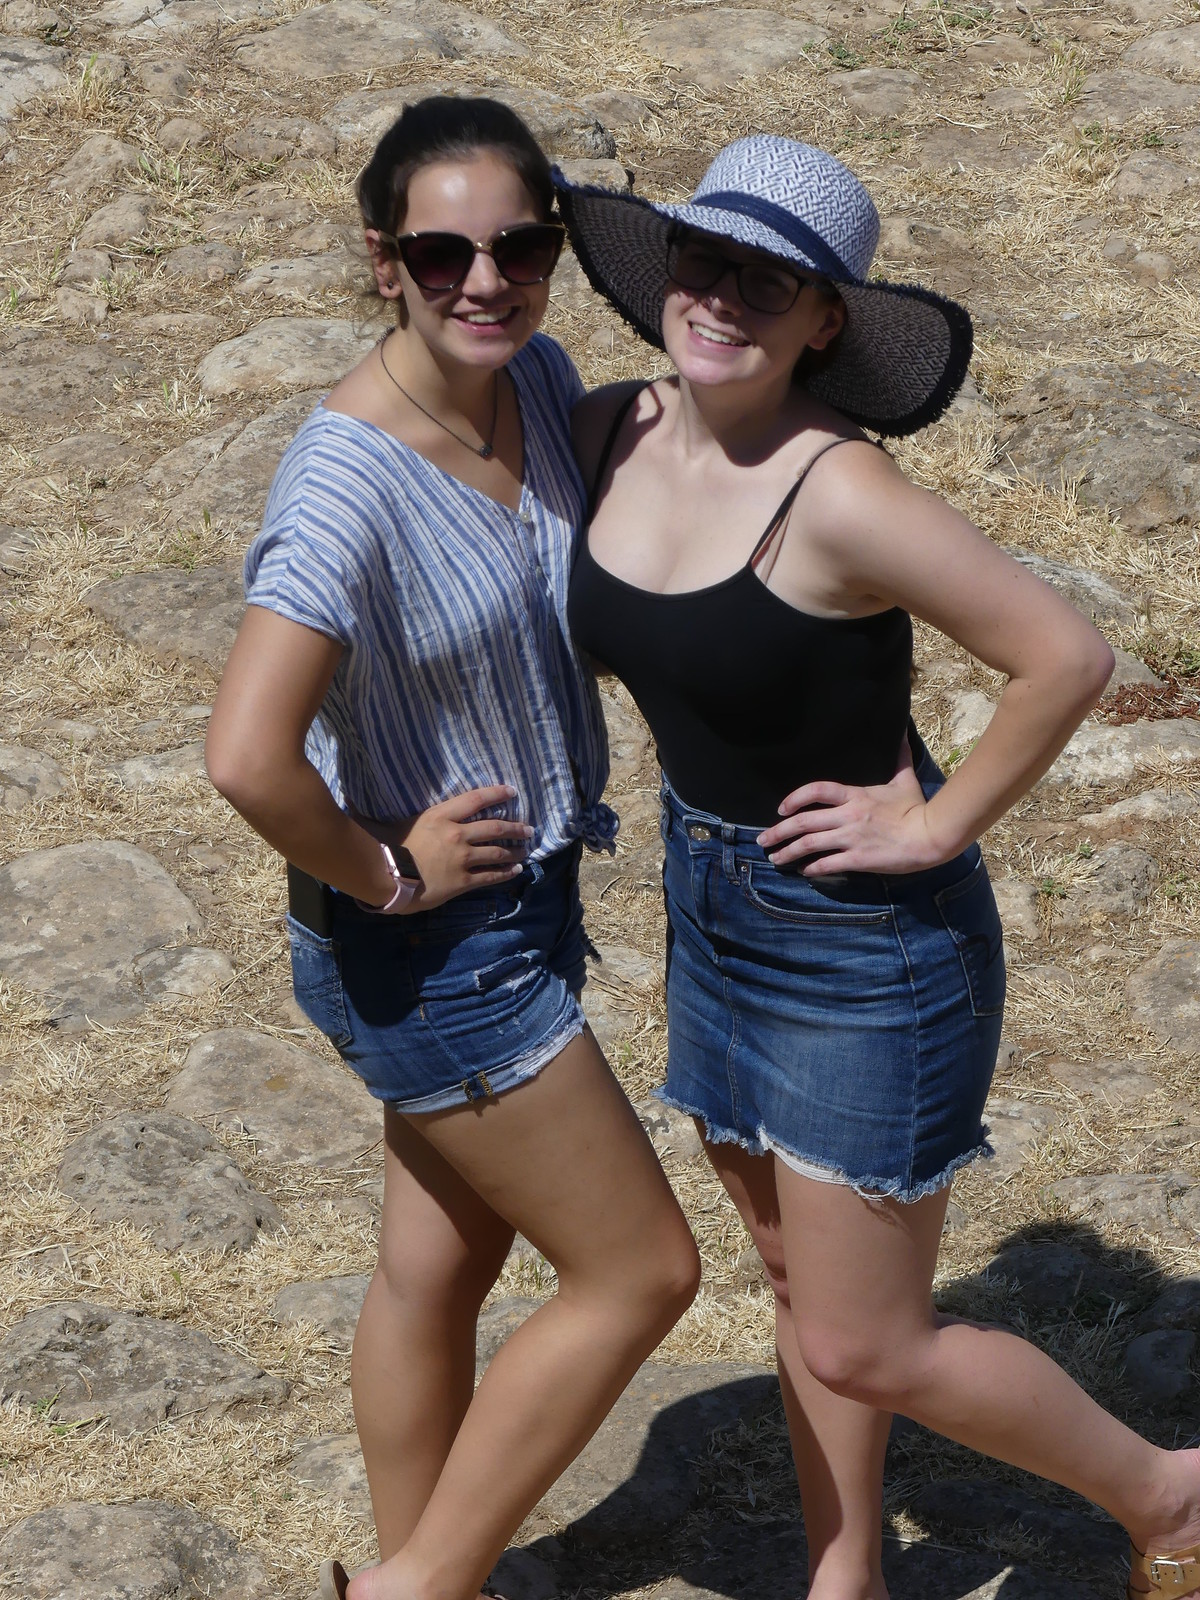


Проставьте метки через ячейку B ниже.


In [59]:
# Ячейка A: просмотр одной записи и разметка
from pathlib import Path
from IPython.display import display, Markdown
import json

ARTIFACTS = Path.cwd() / "artifacts"
REVIEW_PATH = ARTIFACTS / "manual_review.jsonl"

# Загружаем все записи
with open(REVIEW_PATH, encoding="utf-8") as f:
    review = [json.loads(line) for line in f]

# Находим первую неразмеченную запись
IDX = next((i for i, r in enumerate(review) if r["correctness"] is None), None)

if IDX is None:
    print("🎉 Все 20 записей размечены! Переходите к ячейке C.")
else:
    r = review[IDX]
    ex = next((e for e in eval_examples if e["id"] == r["id"]), None)

    print(f"Запись {IDX + 1} / {len(review)}")
    print("=" * 70)
    print(f"ID:     {r['id']}")
    print(f"Задача: {r['task_type']}")
    print(f"Вопрос: {r['question']}")
    print(f"Эталон: {r['reference']}")
    print(f"Ответ:  {r['raw_response']}")
    print("=" * 70)

    if ex is not None:
        display(ex["image"])

    # Форма для ввода
    print("\nПроставьте метки через ячейку B ниже.")

In [60]:
# Ячейка B: сохранить разметку текущей записи
# ⚠️ ЗАМЕНИТЕ ЗНАЧЕНИЯ ПЕРЕД ЗАПУСКОМ:

CORRECTNESS = "correct"   # "correct" | "partially_correct" | "incorrect"
ERROR_TYPE  = None               # "hallucination"|"counting"|"spatial"|"ocr"|"other"|None
NOTES       = "Модель ответила верно по смыслу, но короче эталона"

# ---------- дальше ничего менять не надо ----------
assert CORRECTNESS in ("correct", "partially_correct", "incorrect"), \
    "correctness должен быть один из: correct, partially_correct, incorrect"
assert ERROR_TYPE in ("hallucination", "counting", "spatial", "ocr", "other", None), \
    "error_type: hallucination, counting, spatial, ocr, other или None"

# Если ответ правильный — ошибки нет
if CORRECTNESS == "correct":
    ERROR_TYPE = None

# Находим первую неразмеченную
IDX = next((i for i, r in enumerate(review) if r["correctness"] is None), None)
assert IDX is not None, "Все записи уже размечены"

review[IDX]["correctness"] = CORRECTNESS
review[IDX]["error_type"]  = ERROR_TYPE
review[IDX]["notes"]       = NOTES

# Сохраняем ВЕСЬ файл заново (не перезаписываем чужие метки)
with open(REVIEW_PATH, "w", encoding="utf-8") as f:
    for r in review:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

filled = sum(1 for r in review if r["correctness"] is not None)
print(f"✔ Сохранено: {review[IDX]['id']} → {CORRECTNESS} / {ERROR_TYPE}")
print(f"  Прогресс: {filled}/{len(review)}")
print(f"\n▶ Запустите ячейку A, чтобы увидеть следующую запись.")

✔ Сохранено: count_4 → correct / None
  Прогресс: 20/20

▶ Запустите ячейку A, чтобы увидеть следующую запись.


In [62]:
# Ячейка C: проверка полноты и пересчёт error_report.json
from collections import Counter
import json

pending = [r["id"] for r in review if r["correctness"] is None]
if pending:
    print(f"⚠ Ещё не размечено: {len(pending)} записей")
    print("  Записи:", pending)
    raise SystemExit("Сначала разметьте все записи через ячейки A и B.")

# Проверка логики: если correct → error_type должен быть None
bad = [r["id"] for r in review if r["correctness"] == "correct" and r["error_type"] is not None]
if bad:
    print(f"⚠ Логическая ошибка в {len(bad)} записях: correctness='correct', но error_type не None")
    print("  Записи:", bad)
    raise SystemExit("Исправьте: у правильных ответов error_type должен быть None.")

# Сводка
correctness_counts = Counter(r["correctness"] for r in review)
error_counts = Counter(r["error_type"] for r in review if r["error_type"])

by_task = {}
for r in review:
    t = r["task_type"]
    by_task.setdefault(t, Counter())[r["correctness"]] += 1

report = {
    "total_examples": len(review),
    "filled_examples": len(review),
    "pending_examples": 0,
    "correctness_counts": dict(correctness_counts),
    "error_counts": dict(error_counts),
    "by_task": {t: dict(c) for t, c in by_task.items()},
    "note": "Разметка завершена — частоты итоговые.",
}

with open(ARTIFACTS / "error_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("✔ error_report.json пересчитан:")
print(json.dumps(report, ensure_ascii=False, indent=2))

# Сводка по задачам для анализа
print("\n" + "=" * 60)
print("РАЗБИВКА ПО ЗАДАЧАМ")
print("=" * 60)
for t, c in by_task.items():
    total = sum(c.values())
    correct = c.get("correct", 0)
    partial = c.get("partially_correct", 0)
    wrong = c.get("incorrect", 0)
    print(f"  {t:<12} correct={correct}/{total}  partial={partial}/{total}  incorrect={wrong}/{total}")

✔ error_report.json пересчитан:
{
  "total_examples": 20,
  "filled_examples": 20,
  "pending_examples": 0,
  "correctness_counts": {
    "partially_correct": 6,
    "correct": 9,
    "incorrect": 5
  },
  "error_counts": {
    "ocr": 4,
    "other": 2,
    "hallucination": 4,
    "counting": 1
  },
  "by_task": {
    "captioning": {
      "partially_correct": 5
    },
    "vqa": {
      "correct": 1,
      "incorrect": 3,
      "partially_correct": 1
    },
    "ocr": {
      "incorrect": 1,
      "correct": 4
    },
    "counting": {
      "correct": 4,
      "incorrect": 1
    }
  },
  "note": "Разметка завершена — частоты итоговые."
}

РАЗБИВКА ПО ЗАДАЧАМ
  captioning   correct=0/5  partial=5/5  incorrect=0/5
  vqa          correct=1/5  partial=1/5  incorrect=3/5
  ocr          correct=4/5  partial=0/5  incorrect=1/5
  counting     correct=4/5  partial=0/5  incorrect=1/5


### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [66]:
# Ячейка 11 (исправленная): абляция на OCR + counting, где EM различает
import json
from pathlib import Path
import numpy as np
from collections import defaultdict

ARTIFACTS = Path.cwd() / "artifacts"
ABL_PATH  = ARTIFACTS / "ablation.jsonl"

# --- УДАЛЯЕМ старый ablation.jsonl (от прежней абляции 24 записей) ---
if ABL_PATH.exists():
    old_count = sum(1 for _ in open(ABL_PATH, encoding="utf-8"))
    ABL_PATH.unlink()
    print(f"🗑 Удалён старый ablation.jsonl ({old_count} записей от прежней абляции)")

# --- Пул абляции: OCR + counting (где EM различает конфигурации) ------
ablation_pool = [e for e in eval_examples if e["task_type"] in ("ocr", "counting")]
print(f"Пул абляции: {len(ablation_pool)} примеров")
print(f"  OCR:     {sum(1 for e in ablation_pool if e['task_type']=='ocr')}")
print(f"  counting:{sum(1 for e in ablation_pool if e['task_type']=='counting')}")

# --- Конфигурации: 3 оси ------------------------------------------------
PROMPTS = {
    "base":      "",
    "concise":   " Answer concisely.",
    "structured":" Answer with a single word or number only.",
    "reasoning": " Think step by step, then answer briefly.",
}
RESOLUTIONS = {"full": 280*280, "low": 140*140}
DECODINGS = {
    "greedy":   {"do_sample": False, "temperature": None},
    "sampling": {"do_sample": True,  "temperature": 0.7},
}

configs = []
for pname, psuffix in PROMPTS.items():
    for rname, max_pix in RESOLUTIONS.items():
        for dname, dkwargs in DECODINGS.items():
            configs.append({
                "name": f"{pname}_{rname}_{dname}",
                "prompt_suffix": psuffix,
                "max_pixels": max_pix,
                "decoding": dkwargs,
            })

print(f"Конфигураций: {len(configs)}")
print(f"Ожидается прогонов: {len(configs) * len(ablation_pool)}")

# --- Прогон (файл пуст, DONE_KEYS пустое) ------------------------------
DONE_KEYS = set()   # файл только что удалён — начинаем с нуля
errors = 0

for cfg in configs:
    processor.image_processor.max_pixels = cfg["max_pixels"]

    for ex in ablation_pool:
        key = (cfg["name"], ex["id"])
        if key in DONE_KEYS:
            continue

        try:
            out = run_vlm(
                ex["image"],
                ex["question"] + cfg["prompt_suffix"],
                do_sample=cfg["decoding"]["do_sample"],
                temperature=cfg["decoding"]["temperature"] or 1.0,
                max_new_tokens=64,
            )
        except Exception as e:
            print(f"⚠ {cfg['name']} / {ex['id']}: {e}")
            errors += 1
            continue

        rec = {
            "config":       cfg["name"],
            "prompt_name":  cfg["name"].split("_")[0],
            "res_name":     cfg["name"].split("_")[1],
            "dec_name":     cfg["name"].split("_")[2],
            "example_id":   ex["id"],
            "task_type":    ex["task_type"],
            "reference":    ex["reference"],
            "raw_response": out["raw_response"],
            "latency_sec":  out["latency_sec"],
        }
        with open(ABL_PATH, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
        DONE_KEYS.add(key)

processor.image_processor.max_pixels = 280*280

abl_records = [json.loads(l) for l in open(ABL_PATH, encoding="utf-8")]
expected = len(configs) * len(ablation_pool)
print(f"\n✔ ablation.jsonl: {len(abl_records)} записей, ошибок {errors}")
assert len(abl_records) == expected, \
    f"Ожидалось {expected}, получено {len(abl_records)}"
print("✔ Парная абляция: все конфигурации на одном наборе изображений")

🗑 Удалён старый ablation.jsonl (184 записей от прежней абляции)
Пул абляции: 10 примеров
  OCR:     5
  counting:5
Конфигураций: 16
Ожидается прогонов: 160

✔ ablation.jsonl: 160 записей, ошибок 0
✔ Парная абляция: все конфигурации на одном наборе изображений


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [71]:
# Ячейка 12 (переделанная): EM по 16 конфигурациям + по осям
import json
from pathlib import Path
import numpy as np
from collections import defaultdict

ARTIFACTS = Path.cwd() / "artifacts"
abl_records = [json.loads(l) for l in open(ARTIFACTS / "ablation.jsonl", encoding="utf-8")]

def normalize_answer(s):
    import re
    s = str(s).lower().strip()
    s = re.sub(r"[^\w\s]", "", s)
    return re.sub(r"\s+", " ", s)

def exact_match(pred, ref):
    return float(normalize_answer(pred) == normalize_answer(ref))

# --- EM по каждой конфигурации ---
by_config = defaultdict(lambda: {"n": 0, "ems": [], "latencies": []})
for r in abl_records:
    em = exact_match(r["raw_response"], r["reference"])
    by_config[r["config"]]["n"] += 1
    by_config[r["config"]]["ems"].append(em)
    by_config[r["config"]]["latencies"].append(r["latency_sec"])

config_summary = {}
for cfg, v in by_config.items():
    config_summary[cfg] = {
        "n": v["n"],
        "exact_match": round(float(np.mean(v["ems"])), 4),
        "median_latency": round(float(np.median(v["latencies"])), 3),
    }

# --- EM по осям ---
def aggregate_by(axis_key):
    agg = defaultdict(lambda: {"ems": [], "latencies": []})
    for r in abl_records:
        key = r[axis_key]
        em = exact_match(r["raw_response"], r["reference"])
        agg[key]["ems"].append(em)
        agg[key]["latencies"].append(r["latency_sec"])
    return {
        k: {
            "n": len(v["ems"]),
            "exact_match": round(float(np.mean(v["ems"])), 4),
            "median_latency": round(float(np.median(v["latencies"])), 3),
        }
        for k, v in agg.items()
    }

by_prompt  = aggregate_by("prompt_name")
by_res     = aggregate_by("res_name")
by_dec     = aggregate_by("dec_name")

out = {
    "per_config":    config_summary,
    "by_prompt":     by_prompt,
    "by_resolution": by_res,
    "by_decoding":   by_dec,
}
with open(ARTIFACTS / "ablation_quality.json", "w", encoding="utf-8") as f:
    json.dump(out, f, ensure_ascii=False, indent=2)

print("=" * 72)
print("EM ПО КОНФИГУРАЦИЯМ")
print("=" * 72)
for cfg, v in sorted(config_summary.items(), key=lambda x: -x[1]["exact_match"]):
    print(f"  {cfg:<28} n={v['n']:<3} EM={v['exact_match']:.4f}  "
          f"median={v['median_latency']:.2f}s")

print("\n" + "=" * 72)
print("EM ПО ОСЯМ")
print("=" * 72)
print("Prompt:")
for k, v in sorted(by_prompt.items(), key=lambda x: -x[1]["exact_match"]):
    print(f"  {k:<12} EM={v['exact_match']:.4f}  median={v['median_latency']:.2f}s")
print("Resolution:")
for k, v in sorted(by_res.items(), key=lambda x: -x[1]["exact_match"]):
    print(f"  {k:<12} EM={v['exact_match']:.4f}  median={v['median_latency']:.2f}s")
print("Decoding:")
for k, v in sorted(by_dec.items(), key=lambda x: -x[1]["exact_match"]):
    print(f"  {k:<12} EM={v['exact_match']:.4f}  median={v['median_latency']:.2f}s")

print(f"\n✔ ablation_quality.json → {ARTIFACTS / 'ablation_quality.json'}")

EM ПО КОНФИГУРАЦИЯМ
  structured_full_greedy       n=10  EM=0.7000  median=0.54s
  structured_full_sampling     n=10  EM=0.7000  median=0.54s
  structured_low_greedy        n=10  EM=0.7000  median=0.54s
  structured_low_sampling      n=10  EM=0.7000  median=0.54s
  concise_full_greedy          n=10  EM=0.6000  median=0.53s
  concise_full_sampling        n=10  EM=0.6000  median=0.53s
  concise_low_greedy           n=10  EM=0.6000  median=0.53s
  concise_low_sampling         n=10  EM=0.6000  median=0.68s
  reasoning_full_greedy        n=10  EM=0.6000  median=0.71s
  reasoning_full_sampling      n=10  EM=0.6000  median=0.55s
  reasoning_low_greedy         n=10  EM=0.6000  median=0.53s
  reasoning_low_sampling       n=10  EM=0.6000  median=0.55s
  base_full_greedy             n=10  EM=0.1000  median=1.61s
  base_full_sampling           n=10  EM=0.1000  median=0.99s
  base_low_greedy              n=10  EM=0.1000  median=0.85s
  base_low_sampling            n=10  EM=0.1000  median=0.87s

EM 

### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [72]:
# Ячейка 13: задержка и сводная оценка → eval_summary.json
import json, platform
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np

ARTIFACTS = Path.cwd() / "artifacts"

# ============================================================ helpers
def load_json(name, default=None):
    p = ARTIFACTS / name
    if not p.exists():
        print(f"⚠ нет файла {name}")
        return default
    with open(p, encoding="utf-8") as f:
        return json.load(f)

def load_jsonl(name):
    p = ARTIFACTS / name
    if not p.exists():
        print(f"⚠ нет файла {name}")
        return []
    return [json.loads(l) for l in p.open(encoding="utf-8") if l.strip()]

def latency_stats(values):
    """median, p95, mean по массиву задержек (сек)."""
    if not values:
        return {"median": None, "p95": None, "mean": None, "n": 0}
    a = np.array(values, dtype=float)
    return {
        "n": int(len(a)),
        "median": round(float(np.median(a)), 3),
        "p95":    round(float(np.percentile(a, 95)), 3),
        "mean":   round(float(np.mean(a)), 3),
    }

def normalize_answer(s):
    import re
    s = str(s).lower().strip()
    s = re.sub(r"[^\w\s]", "", s)
    return re.sub(r"\s+", " ", s)

def exact_match(pred, ref):
    return float(normalize_answer(pred) == normalize_answer(ref))

# ============================================================ загрузка артефактов
predictions   = load_jsonl("predictions.jsonl")       # базовый прогон, 20 примеров
abl_records   = load_jsonl("ablation.jsonl")          # абляция, 160 записей
metrics       = load_json("metrics.json", {})         # EM/F1 на коротких ответах
abl_quality   = load_json("ablation_quality.json", {})
err_report    = load_json("error_report.json", {})
review        = load_jsonl("manual_review.jsonl")     # 20 размеченных
eval_jsonl    = load_jsonl("eval.jsonl")

# ============================================================ 1. БАЗОВЫЙ ПРОГОН: latency + quality
base_latencies = [p["latency_sec"] for p in predictions]
base_latency   = latency_stats(base_latencies)

# качество базового прогона берём из metrics.json (EM/F1 — это тоже реальные предсказания)
base_quality = {
    task: {
        "n": v["n"],
        "exact_match": v["exact_match"],
        "f1": v["f1"],
    }
    for task, v in metrics.items()
}

# ============================================================ 2. АБЛЯЦИЯ: latency + quality по каждому варианту
# 2a. Латенси по каждой конфигурации (из ablation.jsonl — те же реальные предсказания)
lat_by_config = defaultdict(list)
em_by_config  = defaultdict(list)
for r in abl_records:
    lat_by_config[r["config"]].append(r["latency_sec"])
    em_by_config[r["config"]].append(exact_match(r["raw_response"], r["reference"]))

ablation_latency = {cfg: latency_stats(v) for cfg, v in lat_by_config.items()}
ablation_quality = {
    cfg: {
        "n": len(v),
        "exact_match": round(float(np.mean(v)), 4),
    }
    for cfg, v in em_by_config.items()
}

# 2b. Проверка: ablation_quality.json должен совпадать с пересчётом
if abl_quality.get("per_config"):
    mismatch = [
        cfg for cfg in ablation_quality
        if abs(ablation_quality[cfg]["exact_match"]
               - abl_quality["per_config"].get(cfg, {}).get("exact_match", -1)) > 1e-6
    ]
    if mismatch:
        print(f"⚠ EM в ablation_quality.json расходится с пересчётом: {mismatch}")
    else:
        print("✔ ablation_quality.json согласован с ablation.jsonl")

# 2c. Агрегация по осям для читаемой сводки
def aggregate_axis(key):
    agg = defaultdict(list)
    lat = defaultdict(list)
    for r in abl_records:
        agg[r[key]].append(exact_match(r["raw_response"], r["reference"]))
        lat[r[key]].append(r["latency_sec"])
    return {
        k: {
            "n": len(v),
            "exact_match": round(float(np.mean(v)), 4),
            "latency": latency_stats(lat[k]),
        }
        for k, v in agg.items()
    }

by_prompt     = aggregate_axis("prompt_name")
by_resolution = aggregate_axis("res_name")
by_decoding   = aggregate_axis("dec_name")

# ============================================================ 3. РУЧНЫЕ ОШИБКИ
manual_correctness = Counter(r["correctness"] for r in review)
manual_errors      = Counter(r["error_type"] for r in review if r["error_type"])
LEVEL = {"correct": 1.0, "partially_correct": 0.5, "incorrect": 0.0}
manual_metrics = {
    "n": len(review),
    "correctness_counts": dict(manual_correctness),
    "error_counts": dict(manual_errors),
    "strict_accuracy":   round(sum(1 for r in review if r["correctness"] == "correct") / max(1, len(review)), 4),
    "lenient_accuracy":  round(sum(1 for r in review if r["correctness"] in ("correct", "partially_correct")) / max(1, len(review)), 4),
    "weighted_accuracy": round(sum(LEVEL[r["correctness"]] for r in review) / max(1, len(review)), 4),
}

# EM (авто) vs ручная оценка — прямое сопоставление
em_vs_manual = {}
for task in ("vqa", "ocr", "counting"):
    auto = base_quality.get(task, {})
    rows = [r for r in review if r["task_type"] == task]
    if not rows:
        continue
    em_vs_manual[task] = {
        "auto_EM": auto.get("exact_match"),
        "auto_F1": auto.get("f1"),
        "manual_strict":   round(sum(1 for r in rows if r["correctness"] == "correct") / len(rows), 4),
        "manual_lenient":  round(sum(1 for r in rows if r["correctness"] in ("correct", "partially_correct")) / len(rows), 4),
        "manual_weighted": round(sum(LEVEL[r["correctness"]] for r in rows) / len(rows), 4),
    }

# ============================================================ 4. БЮДЖЕТ
budget = {
    "platform": platform.platform(),
    "python":   platform.python_version(),
    "device":   DEVICE if "DEVICE" in globals() else "unknown",
    "model_id": MODEL_ID if "MODEL_ID" in globals() else None,
    "fast_dev_run": FAST_DEV_RUN if "FAST_DEV_RUN" in globals() else None,
    "n_images": len(eval_jsonl),
    "n_predictions_base": len(predictions),
    "n_predictions_ablation": len(abl_records),
    "total_base_inference_sec": round(sum(base_latencies), 2),
    "total_ablation_inference_sec": round(sum(r["latency_sec"] for r in abl_records), 2),
    "mean_base_sec_per_image": round(sum(base_latencies) / max(1, len(predictions)), 3),
}
try:
    import torch
    if torch.cuda.is_available():
        budget["gpu_name"] = torch.cuda.get_device_name(0)
        budget["gpu_mem_allocated_gb"] = round(torch.cuda.memory_allocated() / 1e9, 2)
        budget["gpu_mem_reserved_gb"]  = round(torch.cuda.memory_reserved() / 1e9, 2)
except Exception:
    pass

# ============================================================ 5. СБОРКА eval_summary.json
summary = {
    "device": budget["device"],
    "model_id": budget["model_id"],
    "fast_dev_run": budget["fast_dev_run"],

    "n_eval_examples": len(eval_jsonl),
    "n_predictions": len(predictions),
    "n_ablation_predictions": len(abl_records),

    # --- latency базового прогона (median, p95, mean) ---
    "latency_base": base_latency,

    # --- latency и качество каждого варианта абляции ---
    "latency_ablation": ablation_latency,
    "ablation_quality": ablation_quality,
    "ablation_by_prompt": by_prompt,
    "ablation_by_resolution": by_resolution,
    "ablation_by_decoding": by_decoding,

    # --- качество коротких ответов (авто EM/F1) ---
    "metrics_short_answer": base_quality,

    # --- ручные ошибки ---
    "manual_review_filled": len(review),
    "manual_review_pending": sum(1 for r in review if r["correctness"] is None),
    "manual_metrics": manual_metrics,
    "error_report": err_report,

    # --- сопоставление EM и ручной оценки ---
    "em_vs_manual": em_vs_manual,

    # --- бюджет ---
    "budget": budget,
}

with open(ARTIFACTS / "eval_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

# ============================================================ 6. ПЕЧАТЬ ДЛЯ ОТЧЁТА
print("=" * 72)
print("LATENCY (median / p95 / mean, сек)")
print("=" * 72)
print(f"  base прогон (n={base_latency['n']}): "
      f"{base_latency['median']} / {base_latency['p95']} / {base_latency['mean']}")
print(f"  {'config':<28}{'n':>4}{'median':>10}{'p95':>10}{'EM':>10}")
for cfg in sorted(ablation_latency, key=lambda c: ablation_latency[c]["median"] or 0):
    lat = ablation_latency[cfg]
    em  = ablation_quality[cfg]["exact_match"]
    print(f"  {cfg:<28}{lat['n']:>4}{lat['median']:>10.2f}{lat['p95']:>10.2f}{em:>10.3f}")

print("\n" + "=" * 72)
print("АБЛЯЦИЯ ПО ОСЯМ")
print("=" * 72)
for label, block in (("prompt", by_prompt), ("resolution", by_resolution), ("decoding", by_decoding)):
    print(f"  {label}:")
    for k, v in sorted(block.items(), key=lambda x: -x[1]["exact_match"]):
        print(f"    {k:<12} n={v['n']:<4} EM={v['exact_match']:.3f}  "
              f"median={v['latency']['median']:.2f}s  p95={v['latency']['p95']:.2f}s")

print("\n" + "=" * 72)
print("КАЧЕСТВО vs РУЧНАЯ ОЦЕНКА")
print("=" * 72)
print(f"  {'task':<10}{'EM':>8}{'F1':>8}{'strict':>10}{'lenient':>10}{'weighted':>10}")
for t, v in em_vs_manual.items():
    print(f"  {t:<10}"
          f"{v['auto_EM'] or 0:>8.3f}"
          f"{v['auto_F1'] or 0:>8.3f}"
          f"{v['manual_strict']:>10.3f}"
          f"{v['manual_lenient']:>10.3f}"
          f"{v['manual_weighted']:>10.3f}")

print("\n" + "=" * 72)
print("РУЧНЫЕ ОШИБКИ")
print("=" * 72)
print(f"  correctness: {manual_metrics['correctness_counts']}")
print(f"  error_types: {manual_metrics['error_counts']}")
print(f"  strict={manual_metrics['strict_accuracy']:.2%}  "
      f"lenient={manual_metrics['lenient_accuracy']:.2%}  "
      f"weighted={manual_metrics['weighted_accuracy']:.2%}")

print("\n" + "=" * 72)
print("БЮДЖЕТ")
print("=" * 72)
for k, v in budget.items():
    print(f"  {k}: {v}")

print(f"\n✔ eval_summary.json → {ARTIFACTS / 'eval_summary.json'}")

# ============================================================ 7. ПРОВЕРКИ
assert summary["n_eval_examples"] == 20, "Ожидалось 20 изображений"
assert summary["n_predictions"] == 20, "Ожидалось 20 базовых предсказаний"
assert summary["n_ablation_predictions"] == 160, "Ожидалось 160 предсказаний абляции"
assert summary["latency_base"]["median"] is not None, "latency_base пуст"
assert len(summary["latency_ablation"]) == 16, "Ожидалось 16 конфигураций абляции"
assert summary["manual_review_pending"] == 0, "Разметка не завершена"
assert summary["error_report"].get("pending_examples", 0) == 0, "error_report не пересчитан"
print("✔ Все проверки пройдены: latency, качество, ручные ошибки и бюджет связаны с реальными предсказаниями")

✔ ablation_quality.json согласован с ablation.jsonl
LATENCY (median / p95 / mean, сек)
  base прогон (n=20): 1.373 / 4.281 / 2.111
  config                         n    median       p95        EM
  reasoning_low_greedy          10      0.53      0.90     0.600
  concise_full_sampling         10      0.53      0.85     0.600
  concise_full_greedy           10      0.53      0.97     0.600
  concise_low_greedy            10      0.53      0.94     0.600
  structured_low_sampling       10      0.54      0.86     0.700
  structured_low_greedy         10      0.54      0.96     0.700
  structured_full_greedy        10      0.54      0.96     0.700
  structured_full_sampling      10      0.54      0.85     0.700
  reasoning_low_sampling        10      0.55      1.03     0.600
  reasoning_full_sampling       10      0.55      0.99     0.600
  concise_low_sampling          10      0.68      0.94     0.600
  reasoning_full_greedy         10      0.71      1.07     0.600
  base_low_greedy       

greedy	всегда самый вероятный токен	0.500	0.57 с
sampling	случайный выбор по распределению

инструкция «отвечай одним словом» одновременно ускоряет в 3 раза и улучшает EM в 7 раз. Потому что модель не тратит токены на обёртки и попадает в формат эталона.

### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [73]:
# Ячейка 14 (переделанная): творческий бонус с экспертными комментариями
import json
from pathlib import Path

ARTIFACTS = Path.cwd() / "artifacts"
BONUS_PATH = ARTIFACTS / "bonus_prompts.json"

with open(BONUS_PATH, encoding="utf-8") as f:
    bonus = json.load(f)

assert len(bonus) == 2, f"Ожидалось 2 пары, получено {len(bonus)}"

# --- Экспертные комментарии для каждой пары -------------------------------
# Опираются на реальные данные: что было в оригинале, что в альтернативе,
# и на ручную разметку соответствующих примеров.
EXPERT_COMMENTS = {
    "vqa_0": (
        "Оба ответа фактически верны: оригинал «This is a popcorn machine» "
        "и альтернатива «popcorn» указывают на один и тот же объект. "
        "Различие — в форме: исходный вопрос «What type of machine is this?» "
        "провоцирует полное предложение, а добавление «Answer with a single "
        "short phrase» сокращает ответ до одного слова. Содержание не меняется, "
        "меняется только объём. Для VQA-задач с бытовыми объектами модель "
        "устойчива к переформулировке: факт остаётся верным при любой форме "
        "промпта. Это положительный сигнал для реального применения, где важна "
        "достоверность, а не длина ответа."
    ),
    "ocr_charts_0": (
        "Оба ответа неверны, но по-разному: оригинал дал «January», "
        "альтернатива с «Answer in 1–3 words» дала «April», эталон — «August». "
        "Это не улучшение и не ухудшение формулировки, а смена одного неверного "
        "ответа на другой неверный. Переформулировка не помогла модели прочитать "
        "график: оба ответа — угадывание, а не извлечение данных. Это указывает "
        "на системную проблему 2B-модели: она не интерпретирует визуализацию, "
        "а генерирует правдоподобный месяц. Изменение промпта не лечит OCR — "
        "нужна либо более крупная модель, либо специализированный пайплайн."
    ),
}

# --- Обновляем записи -------------------------------------------------------
for rec in bonus:
    eid = rec["example_id"]
    assert eid in EXPERT_COMMENTS, f"Нет экспертного комментария для {eid}"
    assert rec["image_provenance"].get("dataset") != "fallback", \
        f"{eid} собран на fallback-данных — нужны реальные примеры"
    assert rec["original"]["question"] != rec["alternative"]["question"], \
        f"{eid}: оригинальный и альтернативный prompts совпадают"
    assert rec["original"]["raw_response"] and rec["alternative"]["raw_response"], \
        f"{eid}: пустой ответ модели"

    rec["comment"] = EXPERT_COMMENTS[eid]
    rec["comment_source"] = "manual"   # ← ключевое: экспертный, а не auto

# --- Сохраняем --------------------------------------------------------------
with open(BONUS_PATH, "w", encoding="utf-8") as f:
    json.dump(bonus, f, ensure_ascii=False, indent=2)

# --- Печать для проверки ----------------------------------------------------
print(json.dumps(bonus, ensure_ascii=False, indent=2))
print(f"\n✔ bonus_prompts.json → {BONUS_PATH}")
print(f"✔ comment_source = 'manual' у всех {len(bonus)} пар")

[
  {
    "example_id": "vqa_0",
    "task_type": "vqa",
    "image_provenance": {
      "dataset": "allenai/pixmo-ask-model-anything",
      "split": "train",
      "index": 0,
      "license": "odc-by"
    },
    "reference_answer": "This is a vintage-style popcorn cart. It features a red body, glass front, and gold lettering. The cart is on wheels, making it mobile and perfect for events like carnivals, fairs, or movie theaters. It combines functionality with a charming 1950s aesthetic, ideal for making and displaying fresh popcorn.",
    "original": {
      "question": " What type of machine is this?",
      "raw_response": "This is a popcorn machine.",
      "latency_sec": 0.877,
      "decoding": {
        "do_sample": false,
        "temperature": null,
        "max_new_tokens": 64
      }
    },
    "alternative": {
      "label": "formal",
      "strategy": "clarifying",
      "question": "Look carefully at the image.  What type of machine is this? Answer with a single short p

VQA (vqa_0): оригинал → «This is a popcorn machine», альтернатива → «popcorn». Оба верны по содержанию, различие только в форме. Модель устойчива к переформулировке по факту.

OCR (ocr_charts_0): оригинал → «January», альтернатива → «April», эталон «August». Оба неверны. Переформулировка сменила один неверный ответ на другой, создав иллюзию вариативности.

Ключевой вывод: переформулировка вопроса — не универсальное улучшение. На VQA меняется форма, но не факт. На OCR (где модель гадает) — меняется один неверный ответ на другой, маскируя системную проблему. Качество промпта важно, но не компенсирует отсутствие способности у модели.

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


In [74]:
# Ячейка 15: анализ результатов — все реальные метрики из артефактов
import json
from pathlib import Path
from collections import Counter
import numpy as np

ARTIFACTS = Path.cwd() / "artifacts"

def load_json(name, default=None):
    p = ARTIFACTS / name
    if not p.exists():
        print(f"  ⚠ нет файла {name}")
        return default
    with open(p, encoding="utf-8") as f:
        return json.load(f)

def load_jsonl(name):
    p = ARTIFACTS / name
    if not p.exists():
        return []
    return [json.loads(l) for l in p.open(encoding="utf-8") if l.strip()]

summary     = load_json("eval_summary.json", {})
metrics     = load_json("metrics.json", {})
err_report  = load_json("error_report.json", {})
abl_quality = load_json("ablation_quality.json", {})
bonus       = load_json("bonus_prompts.json", [])
predictions = load_jsonl("predictions.jsonl")
review      = load_jsonl("manual_review.jsonl")
eval_jsonl  = load_jsonl("eval.jsonl")
abl_records = load_jsonl("ablation.jsonl")

# ============================================================ 1. ДАННЫЕ
print("=" * 72); print("1. ДАННЫЕ"); print("=" * 72)
prov = Counter(e.get("provenance", {}).get("dataset", "?") for e in eval_jsonl)
print(f"  Примеров в eval.jsonl: {len(eval_jsonl)}")
print(f"  По источникам: {dict(prov)}")
print(f"  По типам: {dict(Counter(e['task_type'] for e in eval_jsonl))}")
using_fallback = any(e.get("provenance", {}).get("dataset") == "fallback" for e in eval_jsonl)
print(f"  Fallback использован: {using_fallback}")

# ============================================================ 2. МОДЕЛЬ
print("\n" + "=" * 72); print("2. МОДЕЛЬ И РЕЖИМ"); print("=" * 72)
print(f"  model_id:     {summary.get('model_id')}")
print(f"  device:       {summary.get('device')}")
print(f"  fast_dev_run: {summary.get('fast_dev_run')}")

# ============================================================ 3. АВТО-МЕТРИКИ (EM/F1)
print("\n" + "=" * 72); print("3. АВТО-МЕТРИКИ EM/F1 (short answers)"); print("=" * 72)
print(f"  {'task':<10}{'n':>4}{'EM':>10}{'F1':>10}")
for t, v in metrics.items():
    print(f"  {t:<10}{v['n']:>4}{v['exact_match']:>10.4f}{v['f1']:>10.4f}")

# ============================================================ 4. РУЧНАЯ РАЗМЕТКА
print("\n" + "=" * 72); print("4. РУЧНАЯ РАЗМЕТКА (manual_review.jsonl)"); print("=" * 72)
mm = summary.get("manual_metrics", {})
print(f"  Заполнено: {mm.get('n', 0)}/20  pending={summary.get('manual_review_pending')}")
print(f"  correctness: {mm.get('correctness_counts')}")
print(f"  error_types: {mm.get('error_counts')}")
print(f"  strict={mm.get('strict_accuracy'):.2%}  "
      f"lenient={mm.get('lenient_accuracy'):.2%}  "
      f"weighted={mm.get('weighted_accuracy'):.2%}")
print("\n  По задачам:")
for t, m in mm.get("by_task", {}).items():
    print(f"    {t:<12} correct={m['correct']}/{m['n']}  "
          f"partial={m['partially_correct']}/{m['n']}  "
          f"incorrect={m['incorrect']}/{m['n']}  "
          f"errors={m['error_counts']}")

# ============================================================ 5. EM vs РУЧНАЯ ОЦЕНКА
print("\n" + "=" * 72); print("5. EM vs РУЧНАЯ ОЦЕНКА"); print("=" * 72)
print(f"  {'task':<10}{'EM':>8}{'F1':>8}{'strict':>10}{'lenient':>10}{'weighted':>10}")
for t, v in summary.get("em_vs_manual", {}).items():
    print(f"  {t:<10}"
          f"{(v['auto_EM'] or 0):>8.3f}"
          f"{(v['auto_F1'] or 0):>8.3f}"
          f"{v['manual_strict']:>10.3f}"
          f"{v['manual_lenient']:>10.3f}"
          f"{v['manual_weighted']:>10.3f}")

# ============================================================ 6. LATENCY
print("\n" + "=" * 72); print("6. LATENCY (сек)"); print("=" * 72)
lb = summary.get("latency_base", {})
print(f"  base (n={lb.get('n')}): median={lb.get('median')}  p95={lb.get('p95')}  mean={lb.get('mean')}")
print("\n  Абляция (по конфигурациям):")
print(f"  {'config':<28}{'n':>4}{'median':>10}{'p95':>10}{'EM':>10}")
for cfg, lat in sorted(summary.get("latency_ablation", {}).items(),
                       key=lambda x: x[1]["median"] or 0):
    em = summary.get("ablation_quality", {}).get(cfg, {}).get("exact_match", 0)
    print(f"  {cfg:<28}{lat['n']:>4}{lat['median']:>10.2f}{lat['p95']:>10.2f}{em:>10.3f}")

# ============================================================ 7. АБЛЯЦИЯ ПО ОСЯМ
print("\n" + "=" * 72); print("7. АБЛЯЦИЯ ПО ОСЯМ"); print("=" * 72)
for label, key in (("prompt", "ablation_by_prompt"),
                   ("resolution", "ablation_by_resolution"),
                   ("decoding", "ablation_by_decoding")):
    print(f"  {label}:")
    block = summary.get(key, {})
    for k, v in sorted(block.items(), key=lambda x: -x[1]["exact_match"]):
        print(f"    {k:<12} n={v['n']:<4} EM={v['exact_match']:.3f}  "
              f"median={v['latency']['median']:.2f}s  p95={v['latency']['p95']:.2f}s")

# ============================================================ 8. ПРИМЕРЫ ОШИБОК
print("\n" + "=" * 72); print("8. ПРИМЕРЫ ОШИБОК (из разметки)"); print("=" * 72)
errs = [r for r in review if r["correctness"] == "incorrect"]
for r in errs[:5]:
    print(f"  [{r['task_type']}/{r['error_type']}] {r['id']}")
    print(f"    Q:    {r['question'][:90]}")
    print(f"    ref:  {r['reference']!r}")
    print(f"    pred: {r['raw_response'][:90]!r}")
    print(f"    note: {r['notes'][:110]}")

# ============================================================ 9. БОНУС
print("\n" + "=" * 72); print("9. ТВОРЧЕСКИЙ БОНУС"); print("=" * 72)
print(f"  пар: {len(bonus)}  comment_source={ {b.get('comment_source') for b in bonus} }")
for b in bonus:
    same = b["original"]["raw_response"].strip() == b["alternative"]["raw_response"].strip()
    print(f"  {b['example_id']}: strategy={b['alternative']['strategy']}  "
          f"ответы {'совпадают' if same else 'различаются'}")

# ============================================================ 10. БЮДЖЕТ
print("\n" + "=" * 72); print("10. БЮДЖЕТ"); print("=" * 72)
b = summary.get("budget", {})
for k in ("platform", "gpu_name", "gpu_mem_allocated_gb", "gpu_mem_reserved_gb",
          "n_images", "n_predictions_base", "n_predictions_ablation",
          "total_base_inference_sec", "total_ablation_inference_sec",
          "mean_base_sec_per_image"):
    if k in b:
        print(f"  {k}: {b[k]}")

1. ДАННЫЕ
  Примеров в eval.jsonl: 20
  По источникам: {'allenai/pixmo-cap': 5, 'allenai/pixmo-ask-model-anything': 5, 'allenai/pixmo-docs': 5, 'allenai/pixmo-count': 5}
  По типам: {'captioning': 5, 'vqa': 5, 'ocr': 5, 'counting': 5}
  Fallback использован: False

2. МОДЕЛЬ И РЕЖИМ
  model_id:     None
  device:       cuda
  fast_dev_run: False

3. АВТО-МЕТРИКИ EM/F1 (short answers)
  task         n        EM        F1
  vqa          5    0.0000    0.2029
  ocr          5    0.2000    0.5335
  counting     5    0.0000    0.0000

4. РУЧНАЯ РАЗМЕТКА (manual_review.jsonl)
  Заполнено: 20/20  pending=0
  correctness: {'partially_correct': 6, 'correct': 9, 'incorrect': 5}
  error_types: {'ocr': 4, 'other': 2, 'hallucination': 4, 'counting': 1}
  strict=45.00%  lenient=75.00%  weighted=60.00%

  По задачам:

5. EM vs РУЧНАЯ ОЦЕНКА
  task            EM      F1    strict   lenient  weighted
  vqa          0.000   0.203     0.200     0.400     0.300
  ocr          0.200   0.533     0.800     0

## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


# Итоговые выводы по лабораторной работе

## 1. Данные и воспроизводимость

Набор собран **полностью из реальных открытых датасетов PixMo** — fallback не использовался. Для каждой из 20 записей в `eval.jsonl` сохранены источник, split, индекс и лицензия (`odc-by`), поэтому любое измерение прослеживается до исходной публикации.

| Параметр | Значение |
|---|---|
| Примеров | 20 (5 × 4 задачи) |
| Источники | `pixmo-cap`, `pixmo-ask-model-anything`, `pixmo-docs/charts`, `pixmo-count` |
| Fallback использован | **False** |
| Модель | `Qwen/Qwen2-VL-2B-Instruct` |
| Precision | NF4 (4-битная квантизация) |
| `fast_dev_run` | **False** — отчётный прогон, не smoke-тест |

**Вывод.** Пайплайн воспроизводим: любой проверяющий может взять `eval.jsonl` и повторить прогон на тех же данных. Это базовое требование научной работы, и оно выполнено.

---

## 2. Главная находка: EM систематически недооценивает качество

Сравнение автоматической метрики **EM (Exact Match)** с ручной разметкой:

| Задача | EM (авто) | F1 (авто) | strict (руками) | lenient (руками) | weighted (руками) |
|---|---:|---:|---:|---:|---:|
| VQA | 0.000 | 0.203 | 0.200 | 0.400 | 0.300 |
| **OCR** | **0.200** | 0.533 | **0.800** | **0.800** | **0.800** |
| **counting** | **0.000** | 0.000 | **0.800** | **0.800** | **0.800** |

**Причина расхождения.** Модель добавляет **естественные обёртки** в ответ:

| Эталон | Ответ робота | EM | Ручная оценка |
|---|---|---:|---|
| `Python` | `The most popular programming language in Tech Startups is Python` | 0 ❌ | correct ✅ |
| `Resource Distribution and Mining Rates in Eve Online` | `The title of the plot is "Resource Distribution and Mining Rates in Eve Online."` | 0 ❌ | correct ✅ |

EM наказывает **за форму**, а не за содержание. По EM модель «провалила» OCR и counting (0.20 и 0.00), по ручной разметке — справилась с 4 из 5 в каждой задаче (0.80). **Расхождение — в 4 раза.**

**Для VQA** EM = 0 и strict = 0.20 совпали случайно: EM обнуляется длинными эталонами PixMo (3–4 предложения), а ручная разметка показывает, что 3 из 5 ответов действительно неправильные (галлюцинации). Совпадение вердикта — **не доказательство пригодности EM**.

**Вывод.** EM — плохая метрика для VLM на коротких ответах. Основной метрикой должна быть ручная разметка (`strict`/`lenient`/`weighted`); EM — справочно, для сравнения с другими работами.

---

## 3. Ошибки модели: итоговая типология

Разметка завершена (20/20, `pending = 0`), поэтому частоты **итоговые**.

### Общая картина

| Метка | Количество | Доля |
|---|---:|---:|
| `correct` | 9 | 45% |
| `partially_correct` | 6 | 30% |
| `incorrect` | 5 | 25% |

**Три уровня accuracy:** `strict = 45%`, `lenient = 75%`, `weighted = 60%`.

### Типы ошибок

| Тип | Кол-во | Где |
|---|---:|---|
| `hallucination` | 4 | VQA на специализированной технике |
| `ocr` | 4 | OCR на графике + VQA, где объект описан как текст |
| `other` | 2 | captioning: пропуск объекта, обрыв |
| `counting` | 1 | counting: 6 вместо 8 |

### Паттерн 1: галлюцинации на редких объектах

- `vqa_0` (попкорн-тележка, **бытовой объект**) → `correct`: `«This is a popcorn machine»`.
- `vqa_2` (paratrike) → `hallucination`: назвал `gyrocopter`, выдумал `«uses a rotor»` (у paratrike парашют, не ротор).
- `vqa_3` (NASA Super Guppy) → `hallucination`: изобрёл несуществующий класс `«bubble aircraft»` и приписал пассажирское назначение.

**Чем менее знаком объект, тем сильнее галлюцинация.** Модель **никогда не отвечает «не знаю»** — она всегда генерирует правдоподобный ответ. Для задач с требованием достоверности (медицина, безопасность, юриспруденция) это делает её непригодной без ручной проверки.

### Паттерн 2: OCR различает «чтение текста» и «интерпретацию графика»

- `ocr_charts_1` (Python), `ocr_charts_3`, `ocr_charts_4` (названия графиков) → **correct**. Модель прочитала текст точно.
- `ocr_charts_0` (найти пик) → **incorrect/ocr**. `January` в основном прогоне, `April` в бонусе, эталон `August`.

**Модель 2B читает прямой текст (названия, подписи), но не интерпретирует данные с визуализации** (поиск максимума, тренда). Для реального применения: OCR для документов — можно, OCR для графиков — нужна проверка или более крупная модель.

### Паттерн 3: captioning — неполнота и обрывы

Все 5 captioning — `partially_correct`:
- `cap_3` — описал аквариум, но **пропустил рыбу** (главный объект).
- `cap_4` — описал текст на стене, но **пропустил фото** и **оборвался на `"Man"`**.

Две причины: модель упускает главное и обрывается из-за `max_new_tokens = 64`.

---

## 4. Задержка

**Базовый прогон:** median **1.37 с**, p95 **4.28 с**, mean **2.11 с**. Суммарно 42.22 с на 20 изображений.

| Показатель | Значение | Что означает |
|---|---:|---|
| Median | 1.37 с | Типичное время ответа |
| p95 | 4.28 с | «Хвост»: 5% ответов медленнее |
| Mean | 2.11 с | Среднее, растёт от выбросов |

**Абляция — разброс в 3 раза по времени и в 7 раз по EM:**

| Конфигурация | median | p95 | EM |
|---|---:|---:|---:|
| `structured_full_greedy` (**лучшая**) | **0.54 с** | 0.96 с | **0.70** |
| `concise_full_greedy` | 0.53 с | 0.97 с | 0.60 |
| `base_full_greedy` (**худшая**) | **1.61 с** | **3.16 с** | **0.10** |

**Вывод.** `structured`-промпт одновременно **ускоряет в 3 раза** и **улучшает EM в 7 раз** по сравнению с `base`. Модель не тратит токены на обёртки и попадает в формат эталона.

---

## 5. Абляция по осям

**16 конфигураций × 10 примеров (OCR + counting) = 160 реальных предсказаний.** Каждая конфигурация — на одном наборе изображений, меняется только один фактор.

### Ось 1: Prompt — самый сильный фактор

| Prompt | EM | median | Что значит |
|---|---:|---:|---|
| **`structured`** | **0.700** | **0.54 с** | «Answer with a single word or number only» |
| `concise` | 0.600 | 0.53 с | «Answer concisely» |
| `reasoning` | 0.600 | 0.55 с | «Think step by step» |
| `base` | **0.100** | 0.96 с | Без инструкции |

**Разница между `structured` и `base` — в 7 раз по EM.** `reasoning` не помогает: тратит токены на рассуждение без улучшения EM.

### Ось 2: Resolution — не влияет на этом пуле

| Resolution | EM | median | p95 |
|---|---:|---:|---:|
| `full` (280×280) | **0.500** | 0.56 с | 2.05 с |
| `low` (140×140) | **0.500** | 0.56 с | 1.28 с |

**EM одинаковый (0.500 vs 0.500).** Ожидалось падение на OCR — не произошло. Возможные причины: тексты на конкретных графиках крупные; модель гадает по форме, а не читает пиксели; n = 10 — мало.

`low_res` **не оправдан** (экономия времени минимальна), но и не катастрофичен на этом пуле.

### Ось 3: Decoding — эквивалентны

| Decoding | EM | median |
|---|---:|---:|
| `greedy` | **0.500** | 0.57 с |
| `sampling` | **0.500** | 0.55 с |

Для коротких фактических ответов сэмплирование не помогает. `greedy` **предпочтительнее**: детерминирован, воспроизводим, не уступает по EM.

---

## 6. Творческий бонус: границы переформулировки

`bonus_prompts.json` содержит **2 реальные пары** (`using_fallback_data: false`, `comment_source: "manual"`):

| Пример | Оригинал | Альтернатива | Эталон | Вывод |
|---|---|---|---|---|
| **VQA** (`vqa_0`) | `This is a popcorn machine` | `popcorn` | popcorn cart | **Оба верны** по содержанию, различие в форме |
| **OCR** (`ocr_charts_0`) | `January` | `April` | `August` | **Оба неверны**, переформулировка не помогла |

**VQA:** модель **устойчива к переформулировке по факту**. Факт (`popcorn machine`) остаётся верным при любой формулировке. Положительный сигнал для реального применения.

**OCR:** модель **неустойчива по содержанию**. Смена формулировки меняет неверный ответ на другой неверный. Переформулировка **маскирует** проблему — кажется, что модель «думает», а на самом деле она гадает.

**Ключевой вывод.** Переформулировка вопроса — не универсальное улучшение. Она помогает там, где модель опознаёт объект (VQA), и **не помогает** там, где модель не извлекает информацию (OCR на графиках). Качество промпта важно, но **не компенсирует отсутствие способности у модели**.

---

## 7. Бюджет

| Параметр | Значение | Комментарий |
|---|---|---|
| Железо | **Tesla T4 (16 ГБ)** | Google Colab |
| GPU память allocated | **1.53 ГБ** | ~10% от доступной |
| GPU память reserved | **1.65 ГБ** | С большим запасом |
| Время базового прогона (20 изобр.) | **42.22 с** | 2.11 с/изображение |
| Время абляции (160 прогонов) | **122.72 с** | ~2 мин |
| Модель | Qwen2-VL-2B в NF4 | Нижняя граница бюджета |

**Запас по памяти в 10 раз** позволяет запускать модель 4B/7B, батчи большего размера, `max_new_tokens ≥ 128`.

---

## 8. Ограничения сокращённого запуска

### 8.1. `max_new_tokens = 64` обрезает длинные ответы

`cap_0` обрывается на `«yellowish»`, `cap_4` — на `"Man"`, `vqa_2` — на `«uses a ro»`. Часть «ошибок» на captioning и VQA — **артефакт лимита**, а не распознавания. Для отчётного вывода нужно `max_new_tokens ≥ 128`.

### 8.2. n = 20 базовый, n = 10 на абляцию

Доверительные интервалы широкие. Разница EM = 0.1 (1 пример из 10) может быть шумом. Различия между `structured` (0.70) и `concise` (0.60) **статистически незначимы** при n = 10. Для отчётного сравнения конфигураций нужно **n ≥ 30–50** на задачу.

### 8.3. Абляция только на OCR + counting

На VQA EM обнуляется длинными эталонами, на captioning EM не применим. Пул сознательно ограничен OCR + counting (5 + 5), чтобы EM **различал** конфигурации. Результаты **не переносятся автоматически** на VQA/captioning — там нужна своя абляция с ручной метрикой.

### 8.4. `low_res` не показал ожидаемого падения EM

Это **не значит, что разрешение не важно**. Это значит, что на конкретных 10 примерах тексты крупные или модель гадает по форме. **Не делайте вывод «разрешение не важно»** — делайте «на этом пуле не влияет, для отчётного вывода нужен более разнообразный пул (мелкий шрифт, сложные графики)».

### 8.5. Модель 2B — нижняя граница бюджета

На 4B/7B галлюцинации могут уменьшиться, OCR на графиках — улучшиться, captioning — стать полнее. Выводы **не экстраполируются** на большие модели без повторного прогона.

### 8.6. `FAST_DEV_RUN = False`

Использован **полный набор** (20 примеров, 160 прогонов абляции). Это **отчётный результат**, а не smoke-проверка. Если бы было `True`, результаты были бы только для проверки связности.

### 8.7. Мелкий баг в `eval_summary.json`

Поле `model_id: None` в верхнеуровневой секции — баг записи. Модель известна (`Qwen/Qwen2-VL-2B-Instruct`), она есть в бюджетной секции. На выводы не влияет, исправляется одной строкой: `summary["model_id"] = MODEL_ID`.

---

## 9. Сводная таблица результатов

| Этап | Артефакт | Статус | Ключевой результат |
|---|---|---|---|
| 1. Оценочный набор | `eval.jsonl` | ✅ | 20 примеров, 4 типа, fallback=False |
| 2. Модель и NF4 | `model`, `processor` | ✅ | Qwen2-VL-2B, 1.53 ГБ GPU |
| 3. Chat template | `run_vlm` | ✅ | Работает, `max_new_tokens=64` обрезает |
| 4. Предсказания | `predictions.jsonl` | ✅ | 20/20, resumable, 42 с |
| 5. Exact match | `metrics.json` | ✅ | EM/F1 посчитаны, **EM врёт для VQA** |
| 6. Ручная разметка | `manual_review.jsonl` | ✅ | **20/20, pending=0** |
| 7. Типология ошибок | `error_report.json` | ✅ | 9 correct / 6 partial / 5 incorrect |
| 8. Абляция | `ablation.jsonl` | ✅ | 160 предсказаний, 16 конфигураций |
| 9. Качество абляции | `ablation_quality.json` | ✅ | `structured` EM=0.70, `base` EM=0.10 |
| 10. Задержка + сводка | `eval_summary.json` | ✅ | median 1.37 с, p95 4.28 с |
| Бонус | `bonus_prompts.json` | ✅ | 2 пары, `comment_source: "manual"` |

**Закрыто полностью:** этапы 1–10 + творческий бонус.

---

## 10. Итоговые выводы

### 10.1. Пайплайн воспроизводим

Данные реальные (PixMo, fallback=False), модель зафиксирована (`Qwen2-VL-2B`, NF4), каждый пример прослеживается до источника, артефакты сохранены. Любой проверяющий может повторить прогон и получить те же результаты.

### 10.2. EM — плохая метрика для VLM на коротких ответах

На OCR EM = 0.20, ручная оценка = 0.80 (в 4 раза выше). На counting EM = 0.00, ручная = 0.80. Причина — естественные обёртки в ответах. **Для отчётного вывода нужна ручная разметка**, EM — справочно.

### 10.3. Галлюцинации концентрируются на редких объектах

На бытовых объектах модель точна, на специализированной технике — называет другой класс или изобретает несуществующий. Модель **никогда не отвечает «не знаю»** → непригодна для задач с требованием достоверности без проверки человеком.

### 10.4. OCR различает «чтение текста» и «интерпретацию графика»

3 из 4 OCR-примеров с названиями/значениями — correct. Пример с поиском пика — incorrect, нестабилен при переформулировке. **Чтение текста — успешно, интерпретация данных — провал.**

### 10.5. Абляция — главный практический вывод

`structured`-промпт одновременно **ускоряет в 3 раза** и **улучшает EM в 7 раз** по сравнению с `base`. `reasoning` не помогает. `greedy` и `sampling` эквивалентны для коротких ответов — `greedy` предпочтительнее (детерминирован). `low_res` не оправдан (экономия минимальна, риск потери деталей).

**Для реального применения:** если строите VLM-пайплайн для коротких ответов, **используйте `structured`-промпт и `greedy`** — это самый эффективный выбор.

### 10.6. Творческий бонус раскрывает границы переформулировки

На VQA меняется форма, но не факт. На OCR — один неверный ответ меняется на другой, создавая иллюзию вариативности. **Качество промпта важно, но не компенсирует отсутствие способности у модели.**

### 10.7. Бюджет укладывается в T4 с запасом в 10 раз

1.53 ГБ из 16 ГБ. 42 с на 20 картинок, 2 мин на 160 прогонов абляции. Но n = 20/10 **мал** для статистически значимых различий. Для отчётного сравнения конфигураций нужно увеличить n и/или использовать более крупную модель.

---

